# Tarea 1 – Limpieza y análisis inicial de datos con Python y Pandas

**Curso:** Seminario de Sistemas 2  
**Dataset:** `dataset_sucio.csv`

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

ModuleNotFoundError: No module named 'pandas'

## 1. Carga del dataset original

In [ ]:
df_original = pd.read_csv("dataset_sucio.csv")
df_original.head(10)

,id_cliente,nombre,genero,fecha_registro,gasto_q,ciudad,categoria
0,502609,Paola Morales,m,2026-02-27,NaN,Antigua,Retail
1,500588,ANA DIAZ,f,2026-02-24,371.80,Villa Nueva,Services
2,502408,Maria Paz,m,2026-01-15,"373,33",quetzaltenango,retail
3,501688,Ana Mejia,f,2026-01-18,361.23,Quetzaltenango,Education
4,502916,Carlos Mendez,f,29/01/2026,"339,01",Amatitlan,Retail
5,504200,Oscar Rojas,m,2026-01-09,138.22,Antigua,RETAIL
6,502029,Isabel Ramirez,m,2026-02-05,"166,31",Villa Nueva,SERVICES
7,501366,Pedro Herrera,m,12/02/2026,"405,62",Amatitlan,Education
8,502614,Patricia Soto,F,2026-01-11,222.88,guatemala,Retail
9,502794,Pablo Perez,M,2026-02-06,"287,37",Escuintla,Retail


## 2. Exploración inicial

In [ ]:
print("Dimensiones originales:", df_original.shape)
print("\nTipos de datos:")
print(df_original.dtypes)
print("\nValores faltantes originales:")
print(df_original.isna().sum())
print("\nDuplicados exactos:", df_original.duplicated().sum())

Dimensiones originales: (5000, 7)

Tipos de datos:
id_cliente         int64
nombre            object
genero            object
fecha_registro    object
gasto_q           object
ciudad            object
categoria         object
dtype: object

Valores faltantes originales:
id_cliente          0
nombre              0
genero             60
fecha_registro      0
gasto_q           505
ciudad            157
categoria           0
dtype: int64

Duplicados exactos: 100


### Observaciones del estado original

Al revisar el dataset se identifican varios problemas de calidad:

- Existen filas duplicadas.
- `genero`, `gasto_q` y `ciudad` contienen valores faltantes o espacios que funcionan como valores vacíos.
- `nombre`, `ciudad` y `categoria` mezclan mayúsculas, minúsculas y espacios sobrantes.
- `fecha_registro` contiene más de un formato de fecha.
- `gasto_q` mezcla punto y coma como separador decimal, por lo que inicialmente se interpreta como texto.

## 3. Limpieza y estandarización

In [ ]:
df = df_original.copy()

# 3.1 Eliminar duplicados exactos
df = df.drop_duplicates().copy()

# 3.2 Estandarizar nombres
df["nombre"] = (
    df["nombre"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.title()
)

# 3.3 Estandarizar género y tratar vacíos
genero = (
    df["genero"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace({"": pd.NA})
)
df["genero"] = (
    genero
    .replace({"M": "Masculino", "F": "Femenino"})
    .fillna("No especificado")
)

# 3.4 Estandarizar fechas
df["fecha_registro"] = pd.to_datetime(
    df["fecha_registro"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# 3.5 Convertir gasto a dato numérico
df["gasto_q"] = pd.to_numeric(
    df["gasto_q"]
    .astype("string")
    .str.strip()
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

# Los valores faltantes de gasto se reemplazan con la mediana,
# porque es una medida robusta ante valores extremos.
mediana_gasto = df["gasto_q"].median()
df["gasto_q"] = df["gasto_q"].fillna(mediana_gasto).round(2)

# 3.6 Estandarizar ciudad y tratar vacíos
ciudad = (
    df["ciudad"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.title()
    .replace({"": pd.NA})
)
df["ciudad"] = ciudad.fillna("No especificada")

# 3.7 Estandarizar categoría
df["categoria"] = (
    df["categoria"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.title()
)

df.head(10)

,id_cliente,nombre,genero,fecha_registro,gasto_q,ciudad,categoria
0,502609,Paola Morales,Masculino,2026-02-27,251.8,Antigua,Retail
1,500588,Ana Diaz,Femenino,2026-02-24,371.8,Villa Nueva,Services
2,502408,Maria Paz,Masculino,2026-01-15,373.33,Quetzaltenango,Retail
3,501688,Ana Mejia,Femenino,2026-01-18,361.23,Quetzaltenango,Education
4,502916,Carlos Mendez,Femenino,2026-01-29,339.01,Amatitlan,Retail
5,504200,Oscar Rojas,Masculino,2026-01-09,138.22,Antigua,Retail
6,502029,Isabel Ramirez,Masculino,2026-02-05,166.31,Villa Nueva,Services
7,501366,Pedro Herrera,Masculino,2026-02-12,405.62,Amatitlan,Education
8,502614,Patricia Soto,Femenino,2026-01-11,222.88,Guatemala,Retail
9,502794,Pablo Perez,Masculino,2026-02-06,287.37,Escuintla,Retail


## 4. Validación del dataset limpio

In [2]:
print("Dimensiones después de la limpieza:", df.shape)
print("\nValores faltantes después de la limpieza:")
print(df.isna().sum())
print("\nDuplicados después de la limpieza:", df.duplicated().sum())
print("\nCategorías estandarizadas:")
print(df["categoria"].value_counts())
print("\nCiudades estandarizadas:")
print(df["ciudad"].value_counts())

NameError: name 'df' is not defined

### Impacto de la limpieza

- El dataset pasó de **5,000** a **4,900** filas debido a la eliminación de **100 duplicados exactos**.
- Los valores de gasto que estaban vacíos se sustituyeron con la **mediana de Q251.80**.
- Los nombres y ciudades quedaron sin espacios sobrantes y con una capitalización uniforme.
- Los valores de género quedaron reducidos a `Masculino`, `Femenino` y `No especificado`.
- Las categorías quedaron estandarizadas en cuatro valores: `Education`, `Food`, `Retail` y `Services`.
- Las fechas quedaron convertidas a un único tipo de dato de fecha.

## 5. Comparación antes y después

In [ ]:
print("ANTES:")
display(df_original.head(10))

print("DESPUÉS:")
display(df.head(10))

ANTES:


,id_cliente,nombre,genero,fecha_registro,gasto_q,ciudad,categoria
0,502609,Paola Morales,m,2026-02-27,NaN,Antigua,Retail
1,500588,ANA DIAZ,f,2026-02-24,371.80,Villa Nueva,Services
2,502408,Maria Paz,m,2026-01-15,"373,33",quetzaltenango,retail
3,501688,Ana Mejia,f,2026-01-18,361.23,Quetzaltenango,Education
4,502916,Carlos Mendez,f,29/01/2026,"339,01",Amatitlan,Retail
5,504200,Oscar Rojas,m,2026-01-09,138.22,Antigua,RETAIL
6,502029,Isabel Ramirez,m,2026-02-05,"166,31",Villa Nueva,SERVICES
7,501366,Pedro Herrera,m,12/02/2026,"405,62",Amatitlan,Education
8,502614,Patricia Soto,F,2026-01-11,222.88,guatemala,Retail
9,502794,Pablo Perez,M,2026-02-06,"287,37",Escuintla,Retail


DESPUÉS:


,id_cliente,nombre,genero,fecha_registro,gasto_q,ciudad,categoria
0,502609,Paola Morales,Masculino,2026-02-27,251.8,Antigua,Retail
1,500588,Ana Diaz,Femenino,2026-02-24,371.8,Villa Nueva,Services
2,502408,Maria Paz,Masculino,2026-01-15,373.33,Quetzaltenango,Retail
3,501688,Ana Mejia,Femenino,2026-01-18,361.23,Quetzaltenango,Education
4,502916,Carlos Mendez,Femenino,2026-01-29,339.01,Amatitlan,Retail
5,504200,Oscar Rojas,Masculino,2026-01-09,138.22,Antigua,Retail
6,502029,Isabel Ramirez,Masculino,2026-02-05,166.31,Villa Nueva,Services
7,501366,Pedro Herrera,Masculino,2026-02-12,405.62,Amatitlan,Education
8,502614,Patricia Soto,Femenino,2026-01-11,222.88,Guatemala,Retail
9,502794,Pablo Perez,Masculino,2026-02-06,287.37,Escuintla,Retail


## 6. Exploración mediante tablas pivote

In [ ]:
tabla_pivote_categoria = df.pivot_table(
    index="categoria",
    values="gasto_q",
    aggfunc=["count", "mean", "sum"]
)

tabla_pivote_categoria.columns = [
    "Cantidad_registros",
    "Gasto_promedio_Q",
    "Gasto_total_Q"
]

tabla_pivote_categoria["Gasto_promedio_Q"] = tabla_pivote_categoria["Gasto_promedio_Q"].round(2)
tabla_pivote_categoria["Gasto_total_Q"] = tabla_pivote_categoria["Gasto_total_Q"].round(2)

tabla_pivote_categoria

,Cantidad_registros,Gasto_promedio_Q,Gasto_total_Q
categoria,,,
Education,1211,249.03,301578.86
Food,1259,254.11,319926.29
Retail,1229,251.12,308629.24
Services,1201,250.94,301381.54


### Interpretación de la tabla pivote

Las cuatro categorías poseen cantidades de registros relativamente similares.  
`Food` presenta el mayor gasto promedio, mientras que las demás categorías se mantienen cercanas entre sí. Esto indica que no existe una diferencia extrema en el gasto promedio entre categorías, aunque sí se observan pequeñas variaciones útiles para el análisis inicial.

In [ ]:
tabla_pivote_ciudad_categoria = df.pivot_table(
    index="ciudad",
    columns="categoria",
    values="gasto_q",
    aggfunc="mean"
).round(2)

tabla_pivote_ciudad_categoria

categoria,Education,Food,Retail,Services
ciudad,,,,
Amatitlan,241.25,229.16,242.19,264.49
Antigua,245.74,253.47,255.63,227.72
Chimaltenango,260.87,261.74,267.86,262.29
Escuintla,269.17,260.48,264.8,275.56
Guatemala,248.24,250.27,226.74,238.74
Mixco,256.44,253.79,244.76,247.56
No especificada,209.7,257.69,241.33,263.81
Quetzaltenango,240.04,278.23,255.91,257.17
Villa Nueva,245.58,243.45,255.54,232.53


### Interpretación por ciudad y categoría

La tabla permite comparar el gasto promedio de cada categoría dentro de cada ciudad.  
Se observan variaciones moderadas entre ciudades; por ejemplo, algunas combinaciones de ciudad y categoría presentan promedios mayores que otras. Esta información sería útil para segmentar análisis posteriores por ubicación.

## 7. Visualizaciones

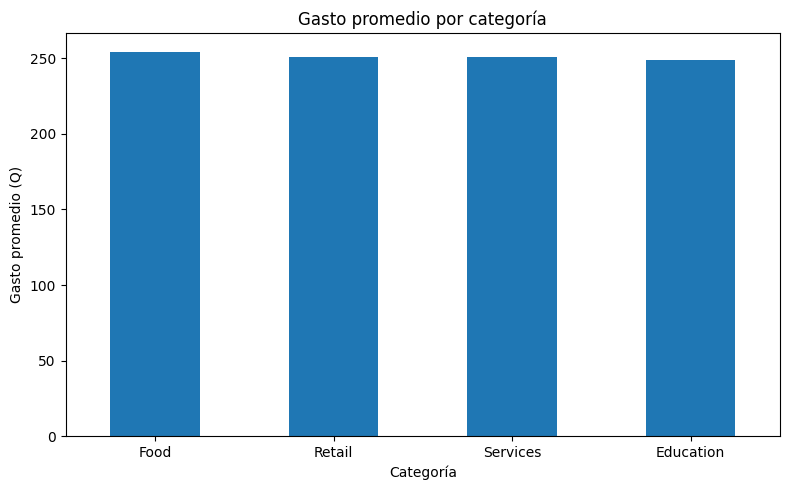

In [ ]:
promedio_categoria = df.groupby("categoria")["gasto_q"].mean().sort_values(ascending=False)

ax = promedio_categoria.plot(kind="bar", figsize=(8, 5))
ax.set_title("Gasto promedio por categoría")
ax.set_xlabel("Categoría")
ax.set_ylabel("Gasto promedio (Q)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretación:** El gasto promedio es bastante cercano entre las categorías. `Food` se ubica ligeramente por encima del resto, por lo que en este conjunto de datos no se evidencia una categoría con un comportamiento de gasto radicalmente distinto.

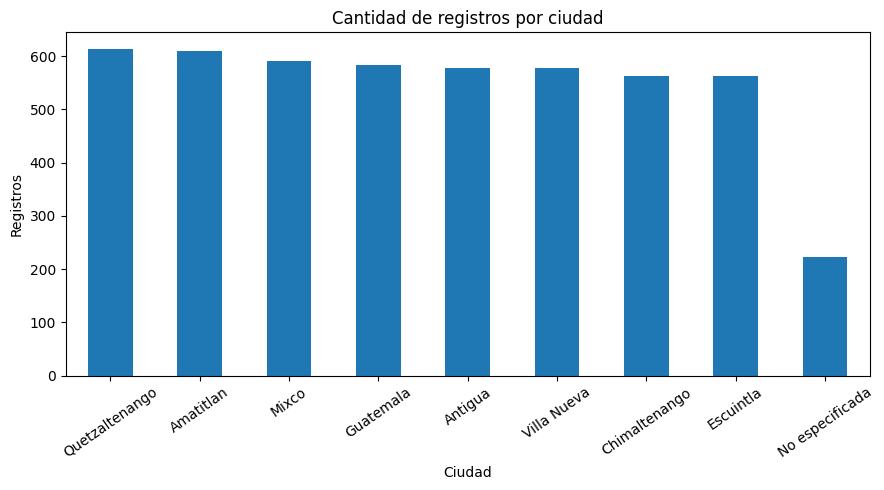

In [ ]:
conteo_ciudad = df["ciudad"].value_counts()

ax = conteo_ciudad.plot(kind="bar", figsize=(9, 5))
ax.set_title("Cantidad de registros por ciudad")
ax.set_xlabel("Ciudad")
ax.set_ylabel("Registros")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

**Interpretación:** La distribución de registros entre las ciudades conocidas es relativamente equilibrada. También queda visible un grupo de registros clasificados como `No especificada`, correspondiente a valores de ciudad que estaban ausentes o vacíos.

## 8. Exportación del dataset limpio

In [ ]:
df_export = df.copy()
df_export["fecha_registro"] = df_export["fecha_registro"].dt.strftime("%Y-%m-%d")
df_export.to_csv("dataset_limpio.csv", index=False, encoding="utf-8-sig")

print("Archivo generado: dataset_limpio.csv")

Archivo generado: dataset_limpio.csv


## Conclusión

La limpieza mejoró la consistencia y utilidad del dataset al eliminar duplicados, tratar valores faltantes y estandarizar textos, fechas y valores numéricos. Después de la depuración, la información puede analizarse de forma más confiable mediante agrupaciones, tablas pivote y visualizaciones. El proceso evidencia la importancia de revisar la calidad de los datos antes de utilizarlos para análisis o toma de decisiones.